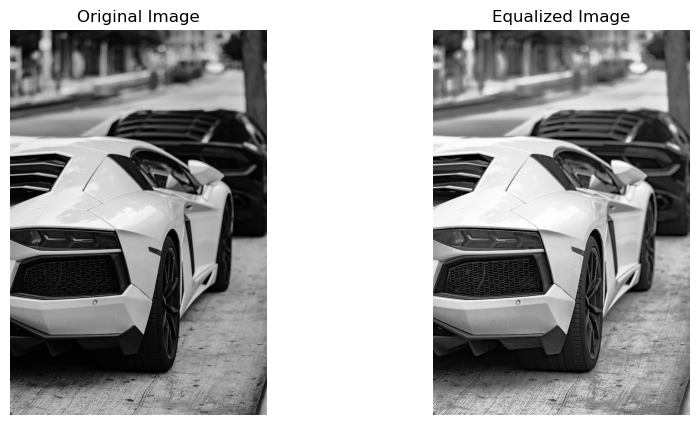

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', 0)
equalized = cv2.equalizeHist(img)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap='gray')
plt.title('Equalized Image')
plt.axis('off')

plt.show()

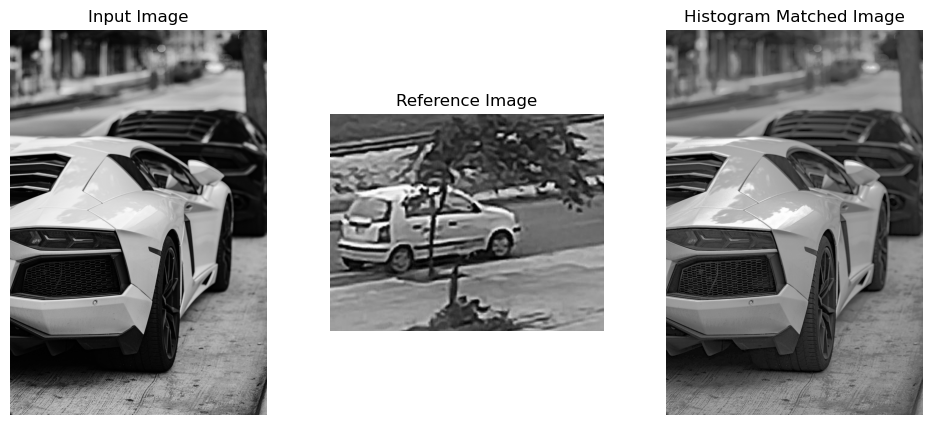

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

input_img = cv2.imread('car.jpg', 0)
reference_img = cv2.imread('reference.jpg', 0)

# Calculate histograms
input_hist = cv2.calcHist([input_img], [0], None, [256], [0, 256])
reference_hist = cv2.calcHist([reference_img], [0], None, [256], [0, 256])

# Calculate cumulative distribution functions (CDF)
input_cdf = input_hist.cumsum()
reference_cdf = reference_hist.cumsum()

# Normalize CDF
input_cdf = input_cdf / input_cdf[-1]
reference_cdf = reference_cdf / reference_cdf[-1]

# Create mapping
mapping = np.interp(input_cdf, reference_cdf, np.arange(256))

# Apply histogram matching
matched_img = cv2.LUT(input_img, mapping.astype(np.uint8))
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap='gray')
plt.title('Input Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(reference_img, cmap='gray')
plt.title('Reference Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title('Histogram Matched Image')
plt.axis('off')

plt.show()